In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df = pd.read_csv('uber.csv')
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [7]:
df = df.drop_duplicates().dropna()

col = ['pickup_longitude', 'pickup_latitude',
        'dropoff_longitude', 'dropoff_latitude',
        'passenger_count', 'fare_amount']

df = df[col]
print(df.shape)

(196977, 6)


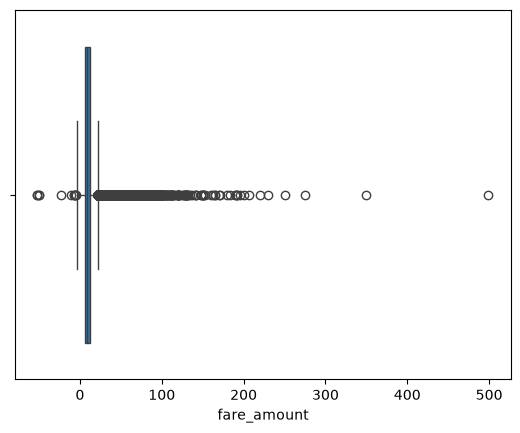

In [9]:
sns.boxplot(x=df['fare_amount'])
plt.show()

Q1 = df.fare_amount.quantile(0.25)
Q3 = df.fare_amount.quantile(0.75)
IQR = Q3 - Q1

df = df[df.fare_amount.between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)]


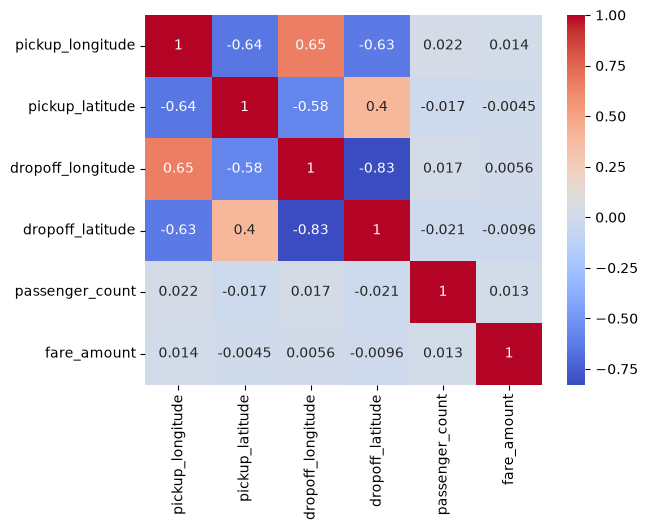

In [10]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

In [11]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()
lr.fit(X_train, y_train)
p1 = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
p2 = rf.predict(X_test)


In [16]:
for name, pred in [('Linear Regression', p1), ('Random Forest', p2)]:
    print(name)
    print('MAE', mean_absolute_error(y_test, pred))
    print('R2:', r2_score(y_test, pred))
    print('RMSE:', np.sqrt(mean_squared_error(y_test, pred)))

Linear Regression
MAE 3.2837643549590854
R2: 0.0005104241045454927
RMSE: 4.124863372089872
Random Forest
MAE 1.5496829598857416
R2: 0.7128850588730037
RMSE: 2.2107942689904836
